# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [5]:
import os

from pandas.api.types import is_string_dtype, is_numeric_dtype

import pandas as pd
import geopandas as gpd

# Display all columns when looking at dfs
pd.set_option('display.max_columns', None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,...,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,...,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,...,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,...,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Create geodataframe from CSV

Known from metadata: CRS of the power plants data has the code EPSG:4269

In [6]:
# Create points from latitude and longitude
points = gpd.points_from_xy(power_plants['longitude'], 
                            power_plants['latitude'])

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants,    # Data
                                geometry=points, # Specify geometry column
                                crs='EPSG:4269'  # Specify CRS
                                )

In [7]:
# CHeck fro geometry column
power_plants.geometry

0         POINT (-84.29497 45.36282)
1         POINT (-83.32781 43.46590)
2         POINT (-82.93881 43.72170)
3         POINT (-85.42600 43.83930)
4         POINT (-85.85510 42.73100)
                    ...             
13440    POINT (-118.10900 34.60800)
13441     POINT (-79.28172 42.50275)
13442     POINT (-77.74272 43.18914)
13443     POINT (-75.90345 42.33782)
13444    POINT (-120.63443 37.08391)
Name: geometry, Length: 13445, dtype: geometry

<Axes: >

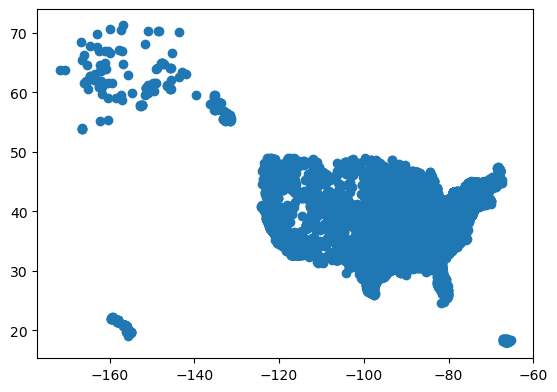

In [ ]:
# Plot data
power_plants.plot()  

## f-strings

f" some text {replace}"

In [ ]:
# Current CRS
print('CRS:', power_plants.crs)

CRS: EPSG:4269


In [12]:
# Explore CRS
print(f"ellipsoid: {power_plants.crs.ellipsoid}")
print(f"datum: {power_plants.crs.datum}")

ellipsoid: GRS 1980
datum: North American Datum 1983


In [13]:
# Any expression can go inside the curly brackets
# :, adds thousands separators
print(f"The data has {len(power_plants):,} power plants in {power_plants['state'].nunique()} states and territories.")

# :.2f rounds to 2 decimals
print(f"Average installed capacity: {power_plants['install_mw'].mean():.2f} MW")

The data has 13,445 power plants in 52 states and territories.
Average installed capacity: 99.39 MW


## Import shapefile

In [14]:
fp = os.path.join('data', 'tl_2026_us_state', 'tl_2026_us_state.shp')
states = gpd.read_file(fp)

states.head(3)

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


EPSG:4269


<Axes: >

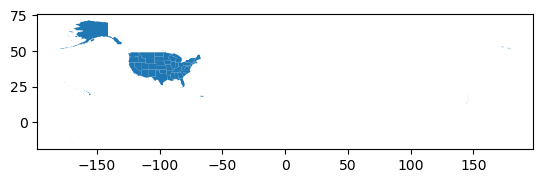

In [ ]:
# Print CRS and plot
print(states.crs)
states.plot()

## `for` loops

In [18]:
# Change columns to lowercase
states.columns = states.columns.str.lower()
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [19]:
# Make list of columns to check
code_cols = ['region', 'division', 'statefp']

# Check whether codes columns are strings
for column in code_cols: 
    print(f"{column} is string dtype? {is_string_dtype(states[column])}")

region is string dtype? True
division is string dtype? True
statefp is string dtype? True


## `assert`

The assert keyword does nothing if the expression next to it evaluates to True. If it evaluates to False, it raises an AssertionError exception and stops your code from running any further. For example:

In [21]:
# Does nothing if statement is True
assert 2+2 == 4

# Raises an error if statement is False
assert 2+2 == 3

AssertionError: 

In [20]:
# Update code columns into integers
for column in code_cols:
    states[column] = states[column].astype('int')
    assert is_numeric_dtype(states[column])  # Check conversion

## Data selection

For this lesson, we want to use only the contiguous states. As seen in the plot, the data covers a bigger area.

### Check-In

- What are the unique values for region, division, or state codes in the data?
- Which codes should we select to keep only states in the contiguous US? - All but 2 (Alaska) and 15 (Hawaii)

In [ ]:
# Print unique values for each of the columns in code_cols
for col in code_cols:
    print(f"Unique {col} values: {states[col].unique()}")

Unique region values: [1 4 9 3 2]
Unique division values: [2 8 9 0 1 5 3 4 6 7]
Unique statefp values: [36 32  2 60 50  9 10 35 37 55 41 31 13  1 49 39 40 47 56 25 51 11 19  4
 48 15 38 21 78 54 12 17 27 24 44 16 33  6 34 45 26  5 28 29 30 20 18 72
 46  8 42 53 22 69 66 23]


In [25]:
# Select contiguous US states
# '~' means 'not' (like '!' in R)
contiguous = states[(states['region']!=9) & (~states['statefp'].isin([2,15]))]
contiguous.head()

,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
4,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.04180 44.156..."
5,1,1,9,01779780,09,0400000US09,CT,Connecticut,00,G4000,A,12542136566,1815978067,+41.5798095,-072.7466313,"POLYGON ((-72.52790 41.17777, -72.55156 41.173..."
6,3,5,10,01779781,10,0400000US10,DE,Delaware,00,G4000,A,5046806302,1399105001,+38.9988742,-075.4422351,"POLYGON ((-75.50949 39.68652, -75.50942 39.686..."


### Check-In

Select the data in the power_plants data frame for the contiguous US states.

In [ ]:
#
contiguous_pp = power_plants